# ДЗ 2.2  Задание 1

По истории профилей SCD2 и справочнику из 25 кампаний определить аудиторию каждой кампании на дату её отправки: домен email пользователя должен совпадать с доменом кампании, а версия профиля — действовать в момент send_at.

Проверяем четыре способа соединения. Сравниваем по пять замеров полной записи в Parquet, без учёта прогрева и подготовки SCD2. 

## 1. Подключение библиотек и проверка окружения

Инициализируем Spark, включаем часовой пояс UTC и настраиваем доступ к RustFS.

In [1]:
import os
import json
import platform
import random
import subprocess
import sys
from pathlib import Path

import pandas as pd
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.sql.types import StructType, StructField, LongType, StringType

from hw22_utils import (
    BASE_DIR, BUCKET, S3_ROOT, ensure_data, configure_s3, s3_client,
    ensure_bucket, s3_object_count, upload_csvs, output_file_count,
    physical_plan, save_plan, write_and_measure, save_measurements,
    spark_ui_status, save_sql_plans_for_jobs,
)

spark = (SparkSession.builder
         .appName('DWH_HW2_2_Task1_Joins')
         .master('local[4]')
         .config('spark.sql.session.timeZone', 'UTC')
         .getOrCreate())
configure_s3(spark)
print('Spark:', spark.version)
assert spark.version.startswith('3.5.'), 'По условию требуется Spark 3.5.x'
print('Spark master:', spark.sparkContext.master)
print('CPU (видимые Python):', os.cpu_count())
print('Память driver:', spark.sparkContext.getConf().get('spark.driver.memory', 'по умолчанию'))
print('Число исполнителей (локальный режим): 1 процесс Spark; рабочие потоки = local[4]')
print('Исходный режим AQE:', spark.conf.get('spark.sql.adaptive.enabled'))
print('Исходный порог авто-broadcast:', spark.conf.get('spark.sql.autoBroadcastJoinThreshold'))
print('Исходное число shuffle-разделов:', spark.conf.get('spark.sql.shuffle.partitions'))

Spark: 3.5.0
Spark master: local[4]
CPU (видимые Python): 20
Память driver: по умолчанию
Число исполнителей (локальный режим): 1 процесс Spark; рабочие потоки = local[4]
Исходный режим AQE: true
Исходный порог авто-broadcast: 10485760b
Исходное число shuffle-разделов: 200


## 2. Исходные кампании

В справочнике есть 25 кампаний- идентификатор, домен, дата отправки и название. Время преобразуем в тип timestamp в UTC. 

In [2]:
task1_dir = ensure_data('task1')
campaign_path = task1_dir / 'campaigns.csv'
campaigns = (spark.read.option('header', True).csv(str(campaign_path))
             .select(F.col('campaign_id').cast('long').alias('campaign_id'),
                     F.lower('email_domain').alias('email_domain'),
                     F.to_timestamp('send_at', "yyyy-MM-dd'T'HH:mm:ssX").alias('send_at'),
                     'campaign_name'))
assert campaigns.count() == 25
assert campaigns.filter('send_at IS NULL').count() == 0
campaigns.orderBy('campaign_id').show(5, truncate=False)

+-----------+---------------+-------------------+-------------+
|campaign_id|email_domain   |send_at            |campaign_name|
+-----------+---------------+-------------------+-------------+
|1          |mail.example   |2026-02-04 09:25:59|Campaign_0001|
|2          |inbox.example  |2026-01-20 07:00:16|Campaign_0002|
|3          |webmail.example|2026-02-15 01:56:37|Campaign_0003|
|4          |webmail.example|2026-02-17 23:41:49|Campaign_0004|
|5          |post.example   |2026-01-07 02:27:37|Campaign_0005|
+-----------+---------------+-------------------+-------------+
only showing top 5 rows



## 3. Генерация журнала событий пользователей
Если файлы уже созданы, генерация пропускается.

In [3]:
event_dir = BASE_DIR / 'event_log_22'
generator = BASE_DIR / 'generate_event_log_1.py'
manifest_path = event_dir / '_manifest.json'
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    assert manifest['total_rows'] == 5_000_000
    assert manifest['user_count'] == 100_000
    assert manifest['seed'] == 42
    assert manifest['file_count'] == 50
    assert manifest['change_probability'] == 0.20
    print('Готовые события найдены:', event_dir)
else:
    if list(event_dir.glob('events_*.csv')):
        raise RuntimeError('Обнаружены неполные файлы без _manifest.json. Очистите event_log_22.')
    subprocess.run([
        sys.executable, str(generator),
        '--rows', '5000000', '--users', '100000',
        '--change-probability', '0.20', '--seed', '42',
        '--start-time', '2026-01-01T00:00:00Z',
        '--max-step-seconds', '1', '--user-id-start', '1',
        '--rows-per-file', '100000',
        '--output-dir', str(event_dir),
    ], check=True)
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
files = sorted(event_dir.glob('events_*.csv'))
assert len(files) == 50, f'Ожидалось 50 CSV, найдено {len(files)}'
print('CSV-файлов:', len(files), 'событий:', manifest['total_rows'])
print('Период:', manifest['first_event_time'], '—', manifest['last_event_time'])

Готовые события найдены: /home/jovyan/work/hw2_2/event_log_22
CSV-файлов: 50 событий: 5000000
Период: 2026-01-01T00:00:01Z — 2026-02-27T20:53:20Z


## 4. Загрузка событий в RustFS



In [4]:
RAW_PREFIX = 'hw22/raw/user_events/'
SOURCE = f's3a://{BUCKET}/{RAW_PREFIX}'
sc3 = ensure_bucket()
remote_file_count = sum(
    1 for page in sc3.get_paginator('list_objects_v2').paginate(Bucket=BUCKET, Prefix=RAW_PREFIX)
    for obj in page.get('Contents', []) if obj['Key'].endswith('.csv')
)
if remote_file_count != 50:
    print('В S3 найдено', remote_file_count, 'CSV. Загружаем 50 файлов...')
    upload_csvs(files, RAW_PREFIX)
else:
    print('Все 50 CSV уже присутствуют в RustFS; загрузка не нужна.')
print('Адрес исходных событий:', SOURCE)

Все 50 CSV уже присутствуют в RustFS; загрузка не нужна.
Адрес исходных событий: s3a://dwh-homework/hw22/raw/user_events/


## 5. Построение SCD2 (аналогично ДЗ 2.1)

Для каждого пользователя сортируем события по времени, сравниваем ФИО, email и логин с предыдущим событием, оставляем только изменения. 

In [5]:
SCD2_PATH = f'{S3_ROOT}/scd2/users/'
REBUILD_SCD2 = False
already_built = output_file_count(SCD2_PATH, sc3) > 0

if REBUILD_SCD2 or not already_built:
    event_schema = StructType([
        StructField('event_time', StringType(), True),
        StructField('user_id', LongType(), True),
        StructField('user_fio', StringType(), True),
        StructField('user_email', StringType(), True),
        StructField('user_login', StringType(), True),
    ])
    events = (spark.read.option('header', True).schema(event_schema).csv(SOURCE)
              .withColumn('event_time', F.to_timestamp('event_time', "yyyy-MM-dd'T'HH:mm:ssX")))
    assert not events.filter('event_time IS NULL OR user_id IS NULL').limit(1).count()
    w = Window.partitionBy('user_id').orderBy('event_time')
    state = F.struct('user_fio', 'user_email', 'user_login')
    changed = (events.withColumn('_state', state)
               .withColumn('_previous', F.lag('_state').over(w))
               .filter(F.col('_previous').isNull() |
                       (~F.col('_state').eqNullSafe(F.col('_previous')))))
    versions = (changed
                .withColumn('valid_from', F.col('event_time'))
                .withColumn('valid_to', F.lead('event_time').over(w))
                .withColumn('is_current', F.col('valid_to').isNull())
                .select('user_id', 'user_fio', 'user_email', 'user_login',
                        'valid_from', 'valid_to', 'is_current'))
    versions.write.mode('overwrite').parquet(SCD2_PATH)
    print('Таблица SCD2 создана и сохранена:', SCD2_PATH)
else:
    print('Используем ранее сохранённую таблицу SCD2:', SCD2_PATH)

scd2 = spark.read.parquet(SCD2_PATH)
print('Число версий:', scd2.count())
print('Уникальных пользователей:', scd2.select('user_id').distinct().count())
assert scd2.select('user_id').distinct().count() == 100_000
assert scd2.filter('is_current = true').count() == 100_000
scd2.orderBy('user_id', 'valid_from').show(5, truncate=False)

Используем ранее сохранённую таблицу SCD2: s3a://dwh-homework/hw22/scd2/users/
Число версий: 1080897
Уникальных пользователей: 100000
+-------+-------------+----------------------------------+----------+-------------------+-------------------+----------+
|user_id|user_fio     |user_email                        |user_login|valid_from         |valid_to           |is_current|
+-------+-------------+----------------------------------+----------+-------------------+-------------------+----------+
|1      |John Scott   |john.scott.1@post.example         |jscott1   |2026-01-01 06:28:21|2026-01-02 12:36:10|false     |
|1      |John Scott   |john.scott.1@post.example         |jscott1r1 |2026-01-02 12:36:10|2026-01-04 06:56:45|false     |
|1      |Brittany Reed|john.scott.1@post.example         |jscott1r1 |2026-01-04 06:56:45|2026-01-22 18:33:05|false     |
|1      |Brittany Reed|brittany.reed.1.r3@webmail.example|jscott1r1 |2026-01-22 18:33:05|2026-01-27 18:39:48|false     |
|1      |Justin Wil

## 6. Условие формирования аудитории

Сравниваем домен email пользователя с доменом кампании. Для каждой кампании берём версию профиля, действовавшую в момент send_at.

INNER JOIN оставляет лишь соответствующие пары.

In [6]:
scd_email = (scd2
             .withColumn('email_domain',
                         F.lower(F.regexp_extract('user_email', r'@([^@]+)$', 1)))
             .select('email_domain', 'user_id', 'user_fio', 'user_email',
                     'user_login', 'valid_from', 'valid_to'))

RESULT_COLUMNS = ['campaign_id', 'campaign_name', 'send_at', 'email_domain',
                  'user_id', 'user_fio', 'user_email', 'user_login']

orig_settings = {
    'spark.sql.adaptive.enabled': spark.conf.get('spark.sql.adaptive.enabled'),
    'spark.sql.autoBroadcastJoinThreshold': spark.conf.get('spark.sql.autoBroadcastJoinThreshold'),
    'spark.sql.shuffle.partitions': spark.conf.get('spark.sql.shuffle.partitions'),
}

def configure_strategy(name):
    if name == 'auto':
        for key, value in orig_settings.items():
            spark.conf.set(key, value)
    else:
        spark.conf.set('spark.sql.adaptive.enabled', 'false')
        spark.conf.set('spark.sql.autoBroadcastJoinThreshold', '-1')
        spark.conf.set('spark.sql.shuffle.partitions', '16')

def audience(name):
    campaign_side = campaigns
    if name == 'merge':
        campaign_side = campaign_side.hint('MERGE')
    elif name == 'broadcast':
        campaign_side = F.broadcast(campaign_side)
    elif name == 'shuffle_hash':
        campaign_side = campaign_side.hint('SHUFFLE_HASH')
    elif name != 'auto':
        raise ValueError('Неизвестная стратегия')
    return (scd_email.join(campaign_side, on='email_domain', how='inner')
            .filter((F.col('valid_from') <= F.col('send_at')) &
                    (F.col('valid_to').isNull() | (F.col('send_at') < F.col('valid_to'))))
            .select(*RESULT_COLUMNS))

configure_strategy('merge')
example = audience('merge')
example.show(5, truncate=False)
print('Бизнес-правило одинаковое во всех четырёх вариантах.')

+-----------+-------------+-------------------+------------+-------+------------+-------------------------------+----------+
|campaign_id|campaign_name|send_at            |email_domain|user_id|user_fio    |user_email                     |user_login|
+-----------+-------------+-------------------+------------+-------+------------+-------------------------------+----------+
|13         |Campaign_0013|2026-01-14 08:02:08|mail.example|7      |Zoe Johnson |zoe.johnson.7.r3@mail.example  |tking7r1  |
|10         |Campaign_0010|2026-01-27 07:16:13|mail.example|26     |Anthony Ross|anthony.ross.26.r3@mail.example|aross26r2 |
|11         |Campaign_0011|2026-01-23 07:18:34|mail.example|26     |Anthony Ross|anthony.ross.26.r3@mail.example|aross26r2 |
|11         |Campaign_0011|2026-01-23 07:18:34|mail.example|34     |Jack Turner |jack.turner.34@mail.example    |jturner34 |
|13         |Campaign_0013|2026-01-14 08:02:08|mail.example|34     |Jack Turner |jack.turner.34@mail.example    |jturner34 |


## 7. Проверка способов соединения таблиц в Spark

Проверяем следующие способы:

- Автоматический
- Sort Merge Join - соединение после распределения и сортировки данных.
- Broadcast Hash Join - небольшой справочник кампаний передаётся каждому исполнителю Spark.
- Shuffled Hash Join - данные перераспределяются по ключу соединения, затем используется хеш-таблица для поиска совпадений.

Для трёх принудительно заданных способов отключаем адаптивную оптимизацию AQE и автоматический выбор Broadcast Join. Число разделов при перераспределении данных устанавливаем равным 16. Для автоматического варианта возвращаем исходные настройки Spark.

Цель проверки - убедиться , что Spark действительно использует выбранные алгоритмы. 

In [7]:
strategies = ['auto', 'merge', 'broadcast', 'shuffle_hash']
for name in strategies:
    configure_strategy(name)
    query = audience(name)
    plan = physical_plan(query)
    save_plan(query, f'task1_plan_{name}.txt')
    expected = {'merge': 'SortMergeJoin', 'broadcast': 'BroadcastHashJoin',
                'shuffle_hash': 'ShuffledHashJoin'}
    if name in expected:
        assert expected[name] in plan, (name, 'Ожидаемый оператор не найден в плане', plan)
    operators = [x for x in ('SortMergeJoin', 'BroadcastHashJoin',
                            'ShuffledHashJoin', 'BroadcastNestedLoopJoin') if x in plan]
    print(name, '| JOIN:', operators,
          '| AQE:', spark.conf.get('spark.sql.adaptive.enabled'),
          '| partitions:', spark.conf.get('spark.sql.shuffle.partitions'))

План сохранён: task1_plan_auto.txt
auto | JOIN: ['BroadcastHashJoin'] | AQE: true | partitions: 200
План сохранён: task1_plan_merge.txt
merge | JOIN: ['SortMergeJoin'] | AQE: false | partitions: 16
План сохранён: task1_plan_broadcast.txt
broadcast | JOIN: ['BroadcastHashJoin'] | AQE: false | partitions: 16
План сохранён: task1_plan_shuffle_hash.txt
shuffle_hash | JOIN: ['ShuffledHashJoin'] | AQE: false | partitions: 16


## 8. Сравнение времени и затрат ресурсов

Для каждого способа выполняем один прогрев и пять измерений в чередующемся порядке. Измеряется полная запись результата в Parquet в S3. Построение SCD2 и проверка правильности результата выполняются отдельно.

По каждому измерению фиксируем время, объём перераспределения данных между задачами (shuffle), объём данных, временно перенесённых из памяти (spill), и число выходных файлов. Данные по отдельным этапам Spark сохраняются в results/task1_stages.csv.

In [ ]:
RUN_BENCHMARKS = True       # False: только открыть существующие csv с измерениями
REQUIRE_UI_METRICS = True  # от повторных замеров без доступа к spark ui
RUNS = 5
assert RUNS >= 5, 'По условию нужно не менее пяти измерений каждого варианта'
results_paths = {name: f'{S3_ROOT}/task1/audiences/{name}/' for name in strategies}

if RUN_BENCHMARKS:
    ui = spark_ui_status(spark)
    print('Spark UI:', ui)
    if REQUIRE_UI_METRICS and not ui['ok']:
        raise RuntimeError('Spark UI REST недоступен: исправьте порт/настройки до измерений')
    measurements = []
    for round_number in range(RUNS + 1):
        order = strategies.copy()
        random.Random(42 + round_number).shuffle(order)
        for name in order:
            configure_strategy(name)
            stats = write_and_measure(spark, audience(name), results_paths[name],
                                      strategy=name, round_number=round_number,
                                      warmup=(round_number == 0))
            stats['aqe'] = spark.conf.get('spark.sql.adaptive.enabled')
            stats['auto_broadcast_threshold'] = spark.conf.get('spark.sql.autoBroadcastJoinThreshold')
            stats['shuffle_partitions'] = spark.conf.get('spark.sql.shuffle.partitions')
            measurements.append(stats)
            print('Прогрев' if round_number == 0 else f'Замер {round_number}',
                  name, f"{stats['seconds']:.3f} с", '| метрики:', stats['metrics_status'])
    raw_metrics, summary = save_measurements(measurements, 'task1')
else:
    raw_metrics = pd.read_csv(BASE_DIR / 'results' / 'task1_measurements.csv')
    summary = pd.read_csv(BASE_DIR / 'results' / 'task1_summary.csv')
    measurements = raw_metrics.to_dict('records')

if 'metrics_status' not in raw_metrics.columns:
    raw_metrics['metrics_status'] = 'Не собрано прежней версией скрипта'

display(raw_metrics[['strategy', 'round', 'warmup', 'seconds', 'shuffle_read_bytes',
                     'shuffle_write_bytes', 'memory_spilled_bytes', 'disk_spilled_bytes',
                     'task_duration_max_median', 'metrics_status']])
display(summary.sort_values('median_seconds'))
missing = raw_metrics.loc[raw_metrics['shuffle_read_bytes'].isna(),
                          ['strategy', 'round', 'metrics_status']]
if len(missing):
    print('ВНИМАНИЕ: не получены метрики для следующих запусков:')
    display(missing)
else:
    print('Для всех запусков получены суммарные метрики Spark UI.')


Spark UI: {'ok': True, 'api_url': 'http://127.0.0.1:4040/api/v1', 'application_id': 'local-1794574149742', 'message': 'Доступен: 31 этапов зарегистрировано'}
Прогрев broadcast 2.471 с | метрики: ok
Прогрев merge 3.840 с | метрики: ok
Прогрев shuffle_hash 5.561 с | метрики: ok
Прогрев auto 4.211 с | метрики: ok
Замер 1 broadcast 4.065 с | метрики: ok
Замер 1 shuffle_hash 21.386 с | метрики: ok
Замер 1 merge 8.580 с | метрики: ok
Замер 1 auto 6.632 с | метрики: ok
Замер 2 merge 8.305 с | метрики: ok
Замер 2 auto 4.673 с | метрики: ok
Замер 2 broadcast 1.646 с | метрики: ok
Замер 2 shuffle_hash 1.937 с | метрики: ok
Замер 3 auto 1.425 с | метрики: ok
Замер 3 shuffle_hash 1.985 с | метрики: ok
Замер 3 merge 2.055 с | метрики: ok
Замер 3 broadcast 1.471 с | метрики: ok
Замер 4 broadcast 1.433 с | метрики: ok
Замер 4 shuffle_hash 1.957 с | метрики: ok
Замер 4 merge 2.029 с | метрики: ok
Замер 4 auto 1.494 с | метрики: ok
Замер 5 shuffle_hash 1.930 с | метрики: ok
Замер 5 merge 1.981 с | метр

,strategy,round,warmup,seconds,shuffle_read_bytes,shuffle_write_bytes,memory_spilled_bytes,disk_spilled_bytes,task_duration_max_median,metrics_status
0,broadcast,0,True,2.471,0,0,0,0,1.00,ok
1,merge,0,True,3.840,50648599,50648599,0,0,32.24,ok
2,shuffle_hash,0,True,5.561,50648599,50648599,0,0,125.81,ok
3,auto,0,True,4.211,0,0,0,0,1.01,ok
4,broadcast,1,False,4.065,0,0,0,0,1.01,ok
5,shuffle_hash,1,False,21.386,50648599,50648599,0,0,804.00,ok
6,merge,1,False,8.580,50648599,50648599,0,0,177.37,ok
7,auto,1,False,6.632,0,0,0,0,1.01,ok
8,merge,2,False,8.305,50648599,50648599,0,0,201.93,ok
9,auto,2,False,4.673,0,0,0,0,1.01,ok


,strategy,runs,median_seconds,min_seconds,max_seconds,shuffle_read_bytes_median,shuffle_write_bytes_median,memory_spilled_bytes_max,disk_spilled_bytes_max,task_duration_max_median_max
0,auto,5,1.494,1.425,6.632,0.0,0.0,0.0,0.0,1.01
1,broadcast,5,1.646,1.433,4.065,0.0,0.0,0.0,0.0,1.01
3,shuffle_hash,5,1.957,1.930,21.386,50648599.0,50648599.0,0.0,0.0,804.00
2,merge,5,2.055,1.981,8.580,50648599.0,50648599.0,0.0,0.0,201.93


Для всех запусков получены суммарные метрики Spark UI.


### 8.1. Проверка окончательного плана автоматического соединения

При включённом AQE Spark может менять физический план после начала выполнения. Можно попробовать сохранить завершённый план из Spark UI.

In [9]:
if RUN_BENCHMARKS:
    aqe_export = save_sql_plans_for_jobs(spark, measurements,
                                         strategy='auto', prefix='task1_auto')
    print('Экспорт планов:', aqe_export)
    if aqe_export['final_aqe_plans'] == 0:
        print('Финальный AQE-план автоматически не получен. Сделайте снимок Spark UI → SQL после исполнения JOIN.')
else:
    print('Замеры не выполнялись; новый окончательный план Spark не создавался.')

Экспорт планов: {'matched_sql_executions': 0, 'final_aqe_plans': 0, 'files': [], 'message': 'API SQL не отдал планов с job ID измерений. Используйте вкладку SQL в Spark UI.'}
Финальный AQE-план автоматически не получен. Сделайте снимок Spark UI → SQL после исполнения JOIN.


In [ ]:
# Сохраним параметры среды и настройки эксперимента
from datetime import datetime, timezone
runtime = {
    'captured_at_utc': datetime.now(timezone.utc).isoformat(),
    'spark_version': spark.version,
    'spark_master': spark.sparkContext.master,
    'python_cpu_count': os.cpu_count(),
    'spark_driver_memory': spark.sparkContext.getConf().get('spark.driver.memory', 'default'),
    'spark_executor_memory': spark.sparkContext.getConf().get('spark.executor.memory', 'default'),
    'spark_default_parallelism': spark.sparkContext.defaultParallelism,
    'number_of_executors_in_local_mode': 1,
    'automatic_settings': orig_settings,
    'explicit_settings': {
        'spark.sql.adaptive.enabled': 'false',
        'spark.sql.autoBroadcastJoinThreshold': '-1',
        'spark.sql.shuffle.partitions': '16',
    },
    'events_count': 5_000_000,
    'users_count': 100_000,
    'campaigns_count': 25,
    'measured_runs_per_strategy': RUNS,
}
(BASE_DIR / 'results' / 'task1_environment.json').write_text(
    json.dumps(runtime, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('Параметры эксперимента сохранены в results/task1_environment.json')

Параметры эксперимента сохранены в results/task1_environment.json


## 9. Проверка совпадения результатов

Четыре стратегии обязаны выдать одинаковую аудиторию. Делаем полное сравнение с помощью exceptAll в обе стороны- функция учитывает и повторяющиеся строки. 

In [11]:
saved = {name: spark.read.parquet(path) for name, path in results_paths.items()}
base = saved['auto']
check_rows = []
for name, df in saved.items():
    missing = base.exceptAll(df).count()
    extra = df.exceptAll(base).count()
    duplicated_pairs = (df.groupBy('campaign_id', 'user_id').count()
                        .filter('count > 1').count())
    rows = df.count()
    part_files = output_file_count(results_paths[name])
    check_rows.append((name, rows, missing, extra, duplicated_pairs, part_files))

checks = pd.DataFrame(check_rows,
                      columns=['strategy', 'rows', 'missing_from_strategy',
                               'extra_in_strategy', 'duplicate_campaign_user',
                               'parquet_files'])
display(checks)
assert (checks[['missing_from_strategy', 'extra_in_strategy',
                'duplicate_campaign_user']] == 0).all().all(), 'Нарушено равенство'
assert (checks['rows'] > 0).all(), 'Аудитория пуста — проверьте даты исходных событий'
checks.to_csv(BASE_DIR / 'results' / 'task1_correctness.csv', index=False)
print('Проверено полное совпадение с учётом повторов.')

,strategy,rows,missing_from_strategy,extra_in_strategy,duplicate_campaign_user,parquet_files
0,auto,500233,0,0,0,4
1,merge,500233,0,0,0,5
2,broadcast,500233,0,0,0,4
3,shuffle_hash,500233,0,0,0,5


Проверено полное совпадение с учётом повторов.


## 10. Выводы по заданию 1

Сформирована аудитория из 500 233 строк. Все четыре варианта соединения дали одинаковый результат и  различий при сравнении в обе стороны с учётом повторов нет; для каждой пары (campaign_id, user_id) не более одной строки. При формировании аудитории использована версия профиля, действовавшая в момент отправки кампании.

Планы и настройки: автоматический способ выбрал BroadcastHashJoin с включённым AQE (200 разделов); явный BROADCAST - тоже BroadcastHashJoin. Подсказки MERGE и SHUFFLE_HASH привели соответственно к SortMergeJoin и ShuffledHashJoin. Для этих трёх явно заданных способов AQE и автоматическая рассылка отключены, число разделов 16.

Время выполнения алгоритмов 

Автоматический JOIN: медиана - 1,494 с, минимум - 1,425 с, максимум - 6,632 с.



Broadcast Hash Join: медиана - 1,646 с, минимум - 1,433 с, максимум - 4,065 с.



Shuffled Hash Join: медиана - 1,957 с, минимум - 1,930 с, максимум - 21,386 с.



Sort Merge Join: медиана - 2,055 с, минимум - 1,981 с, максимум - 8,580 с.

Выбор алгоритма: на этом стенде наименьшая медиана у автоматического соединения 1,494 с. Однако небольшое преимущество по медиане не следует считать гарантированным ускорением.

Перераспределение и память: SortMergeJoin и ShuffledHashJoin в каждом измерении передавали около 50 МБ данных на чтение и столько же на запись при перераспределении. Для вариантов с BroadcastHashJoin эти показатели равны нулю. `Spill` не зарегистрирован ни для одного способа. Следовательно, меньший объём перераспределения не гарантирует пропорционально меньшего полного времени выполнения.

Влияние пяти доменов: при соединении по email_domain есть всего пять разных значений ключа. Это ограничивает эффективный параллелизм соединения с перераспределением по домену. Рассылка небольшого справочника из 25 кампаний позволяет избежать такого перераспределения. Если справочник существенно увеличится или изменятся объём данных и доступная память, наиболее подходящий способ соединения может измениться.

После выполнения запроса в Spark UI проверен окончательный физический план с включённой адаптивной оптимизацией (AQE).


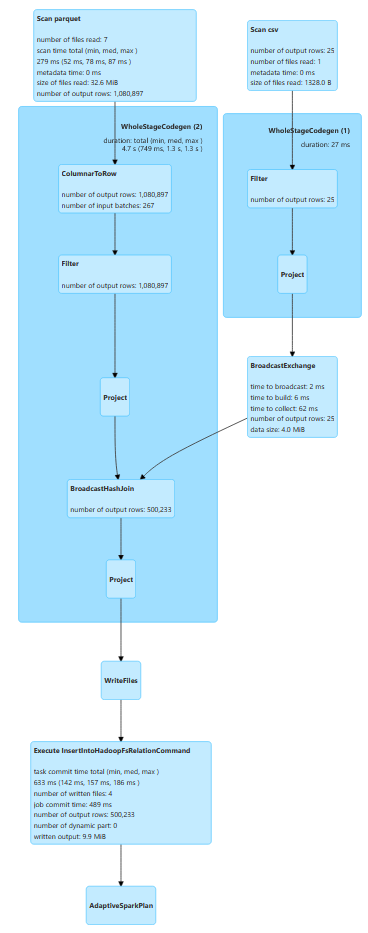